Total records: 150
Total features: 4

Class distribution:
Iris-setosa : 50
Iris-versicolor : 50
Iris-virginica : 50

Training records: 105
Testing records: 45

Randomly initialized weights:
Iris-setosa : [0.2532902065353583, -0.08983201023115395, -0.18765225761663062, -0.24503084377580853]
Bias: -6.85828213149442e-05
Iris-versicolor : [0.09520686694250868, -0.23348169134037744, 0.06387968324159798, -0.3181278841487112]
Bias: 0.4807861245579981
Iris-virginica : [-0.35973358222629115, -0.11074158647089827, 0.3960017130867186, 0.2708269969450303]
Bias: 0.11771007525368882
Epoch: 1 | Test Accuracy: 80.0 %
Epoch: 2 | Test Accuracy: 71.11 %
Epoch: 3 | Test Accuracy: 66.67 %
Epoch: 4 | Test Accuracy: 73.33 %
Epoch: 5 | Test Accuracy: 77.78 %
Epoch: 6 | Test Accuracy: 75.56 %
Epoch: 7 | Test Accuracy: 75.56 %
Epoch: 8 | Test Accuracy: 73.33 %
Epoch: 9 | Test Accuracy: 75.56 %
Epoch: 10 | Test Accuracy: 77.78 %
Epoch: 11 | Test Accuracy: 77.78 %
Epoch: 12 | Test Accuracy: 80.0 %
Epoch: 13 | Tes

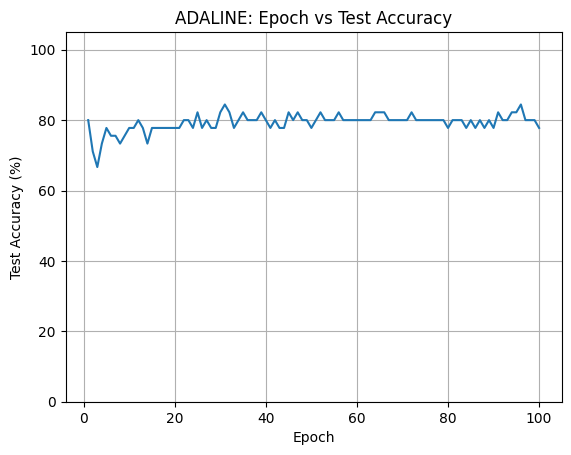

In [1]:
import random
import matplotlib.pyplot as plt


#  Reading the data set

file = open("/content/iris data set.csv", "r")

features = []
labels = []

# Skip header
header = file.readline()

for line in file:

    line = line.strip()

    if line != "":

        values = line.split("\t")


        row = []

        for i in range(4):
            row.append(float(values[i]))

        features.append(row)


        labels.append(values[4])

file.close()

print("Total records:", len(features))
print("Total features:", len(features[0]))





classes = [
    "Iris-setosa",
    "Iris-versicolor",
    "Iris-virginica"
]

print("\nClass distribution:")

for flower in classes:

    count = 0

    for label in labels:

        if label == flower:
            count += 1

    print(flower, ":", count)



# Spliting the data into training and testing




random.seed(35)

train_indices = []
test_indices = []

for flower in classes:

    class_indices = []


    for i in range(len(labels)):

        if labels[i] == flower:
            class_indices.append(i)


    random.shuffle(class_indices)


    train_count = (len(class_indices) * 7) // 10

    for i in range(len(class_indices)):

        if i < train_count:
            train_indices.append(class_indices[i])

        else:
            test_indices.append(class_indices[i])



random.shuffle(train_indices)
random.shuffle(test_indices)

train_features = []
train_labels = []

test_features = []
test_labels = []

for i in train_indices:

    train_features.append(features[i])
    train_labels.append(labels[i])

for i in test_indices:

    test_features.append(features[i])
    test_labels.append(labels[i])


print("\nTraining records:", len(train_features))
print("Testing records:", len(test_features))


# Normalization of data between 0-1


minimum = []
maximum = []

number_of_features = len(features[0])

# Find minimum and maximum for every feature.
# Only training data is used.

for column in range(number_of_features):

    smallest = train_features[0][column]
    largest = train_features[0][column]

    for row in range(len(train_features)):

        value = train_features[row][column]

        if value < smallest:
            smallest = value

        if value > largest:
            largest = value

    minimum.append(smallest)
    maximum.append(largest)


# Normalize training data.

normalized_train = []

for row in range(len(train_features)):

    new_row = []

    for column in range(number_of_features):

        difference = maximum[column] - minimum[column]

        if difference != 0:

            value = (
                train_features[row][column] - minimum[column]
            ) / difference

        else:
            value = 0.0

        new_row.append(value)

    normalized_train.append(new_row)


# Normalize testing data using training minimum and maximum.

normalized_test = []

for row in range(len(test_features)):

    new_row = []

    for column in range(number_of_features):

        difference = maximum[column] - minimum[column]

        if difference != 0:

            value = (
                test_features[row][column] - minimum[column]
            ) / difference

        else:
            value = 0.0

        new_row.append(value)

    normalized_test.append(new_row)



#INITIALIZE RANDOM WEIGHTS AND BIAS



learning_rate = 0.01
number_of_epochs = 100

models = {}

for flower in classes:

    weights = []

    # Randomly initialize four weights.
    for i in range(number_of_features):

         weights.append(random.uniform(-0.5, 0.5))

    # Randomly initialize bias.
    bias = random.uniform(-0.5, 0.5)

    models[flower] = {
        "weights": weights,
        "bias": bias
    }


print("\nRandomly initialized weights:")

for flower in classes:

    print(flower, ":", models[flower]["weights"])

    print("Bias:", models[flower]["bias"])



# CALCULATE ADALINE OUTPUT


def calculate_output(input_values, weights, bias):

    output = bias

    for i in range(number_of_features):

        output = output + (
            weights[i] * input_values[i]
        )

    return output



# TRAIN THE ADALINE MODELS


accuracy_history = []

for epoch in range(number_of_epochs):

    # Train each of the three models.
    for flower in classes:

        weights = models[flower]["weights"]
        bias = models[flower]["bias"]


        row_indices = list(range(len(normalized_train)))
        random.shuffle(row_indices)

        for row in row_indices:

            input_values = normalized_train[row]

            # Assign target value.
            # Current flower = +1
            # Other flowers = -1

            if train_labels[row] == flower:

                target = 1

            else:

                target = -1


            # Calculate continuous ADALINE output.

            output = calculate_output(
                input_values,
                weights,
                bias
            )


            # Calculate error.

            error = target - output


            # Update weights using LMS rule.

            for i in range(number_of_features):

                weights[i] = weights[i] + (
                    learning_rate * error * input_values[i]
                )


            # Update bias.

            bias = bias + learning_rate * error


        # Save updated weights and bias.

        models[flower]["weights"] = weights

        models[flower]["bias"] = bias



# Calulate accuracy after each epoch


    correct = 0

    for row in range(len(normalized_test)):

        highest_output = None
        predicted_flower = None

        # Calculate output from all three ADALINE models.

        for flower in classes:

            weights = models[flower]["weights"]
            bias = models[flower]["bias"]

            output = calculate_output(
                normalized_test[row],
                weights,
                bias
            )

            # Select class with highest output.

            if highest_output is None or output > highest_output:

                highest_output = output
                predicted_flower = flower


        # Compare prediction with actual class.

        if predicted_flower == test_labels[row]:

            correct += 1


    # Calculate accuracy.

    accuracy = (correct / len(test_labels)) * 100

    accuracy_history.append(accuracy)


    print(
        "Epoch:", epoch + 1,
        "| Test Accuracy:", round(accuracy, 2), "%"
    )



# FINAL RESULTS


correct = 0

print("\n========== FINAL ADALINE RESULTS ==========")

for row in range(len(normalized_test)):

    highest_output = None
    predicted_flower = None

    for flower in classes:

        weights = models[flower]["weights"]
        bias = models[flower]["bias"]

        output = calculate_output(
            normalized_test[row],
            weights,
            bias
        )

        if highest_output is None or output > highest_output:

            highest_output = output
            predicted_flower = flower


    actual_flower = test_labels[row]

    if predicted_flower == actual_flower:

        correct += 1


    print(
        "Actual:", actual_flower,
        "| Predicted:", predicted_flower
    )


final_accuracy = (correct / len(test_labels)) * 100

print("\nTraining records:", len(train_features))
print("Testing records:", len(test_features))

print("Correct predictions:", correct)
print("Incorrect predictions:", len(test_labels) - correct)

print("Final Test Accuracy:", round(final_accuracy, 2), "%")


# ------------------------------------------------------------
# 10. PLOT EPOCH VS ACCURACY
# ------------------------------------------------------------

epochs = []

for i in range(number_of_epochs):

    epochs.append(i + 1)


plt.plot(epochs, accuracy_history)

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")

plt.title("ADALINE: Epoch vs Test Accuracy")

plt.grid(True)
plt.ylim(0, 105)

plt.show()